# Task 2: Published Paper Reproducibility Audit

**By:** Margorie Fernanda Pérez Simba   
**Selected Paper:** Albugami, S., Wali, A., & Almagrabi, H. (2026). Predicting student dropout in Saudi Universities using machine learning and explainable AI. PeerJ Computer Science, 12, e3490. https://doi.org/10.7717/peerj-cs.3490

## Objective

This notebook evaluates whether the main performance result reported by Albugami et al. (2026) can be reproduced using the published dataset and source code. It also compares the published procedure with a corrected evaluation designed to prevent data leakage.

## 1- Dataset Loading and Initial Inspection

In [1]:
import pandas as pd

df = pd.read_csv("/content/Saudi_Student_Dropout_Data.csv")

print("Dataset dimensions:", df.shape)
df.head()

Dataset dimensions: (4560, 26)


,Dropout,Gender,Age,Employment Status,Marital Status,Year,University Name,Faculty Name,Program Type,GPA,...,Major Preknowledge,Peer Influence,Family/Employer Pressure,Cultural Expectation,City Moving,Commitments,Living Expenses,Family/Friends Support,Psychological Issues,Health Issues
0,Yes,Female,18 - 25,Unemployed,Single,First Year,JIC,Preparatory year,Free Bachelor,Excellent,...,Yes,Yes,No,No,No,Yes,No,Yes,Yes,Yes
1,No,Female,26 - 33,Unemployed,Single,Above Third Year,KAU,College of CS and IT,Free Master's,Excellent,...,Yes,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes
2,No,Female,26 - 33,Unemployed,Single,First Year,KAU,College of CS and IT,Free Master's,GPA is not showing yet,...,No,No,No,No,No,No,No,Yes,Yes,No
3,No,Female,18 - 25,Unemployed,Single,Graduated,KAU,College of Communication and Media,Free Bachelor,Excellent,...,Yes,No,No,No,No,No,No,No,No,No
4,Yes,Female,18 - 25,Employed full-time,Married,Third Year,KAU,College of CS and IT,Free Master's,Very Good,...,Yes,No,Yes,Yes,No,Yes,Yes,No,Yes,No


## 2- Library Imports

In [2]:
!pip install -q imbalanced-learn xgboost catboost shap lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 3.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 11.0 MB/s eta 0:00:00


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from collections import Counter, defaultdict

from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    VotingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import (
    SelectKBest,
    f_classif,
    chi2,
    RFE,
    mutual_info_classif
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from imblearn.combine import SMOTEENN
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

import shap
import lime
import lime.lime_tabular

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 3- Data Cleaning and Encoding

In [4]:
# Create a copy of the original dataset
df_cleaned = df.copy()

# Remove missing values and duplicated records
df_cleaned = df_cleaned.dropna().drop_duplicates().copy()

# Define the order of ordinal variables
ordinal_columns = {
    "Age": [
        "18 - 25",
        "26 - 33",
        "34 - 41",
        "Above 41"
    ],
    "Year": [
        "First Year",
        "Second Year",
        "Third Year",
        "Above Third Year",
        "Graduated"
    ],
    "GPA": [
        "GPA is not showing yet",
        "Pass",
        "Good",
        "Very Good",
        "Excellent"
    ],
    "Failed Courses": [
        "0",
        "1 - 2",
        "3 - 4",
        "More than 4"
    ]
}

# Encode ordinal variables
for column_name, order in ordinal_columns.items():
    df_cleaned[column_name] = pd.Categorical(
        df_cleaned[column_name],
        categories=order,
        ordered=True
    ).codes

# Encode the remaining categorical variables
encoding_maps = {}

for column_name in df_cleaned.columns:
    if column_name not in ordinal_columns:
        label_encoder = preprocessing.LabelEncoder()
        df_cleaned[column_name] = label_encoder.fit_transform(
            df_cleaned[column_name]
        )
        encoding_maps[column_name] = dict(
            zip(
                label_encoder.classes_,
                label_encoder.transform(label_encoder.classes_)
            )
        )

print("Original dimensions:", df.shape)
print("Cleaned dimensions:", df_cleaned.shape)
print("Dropout encoding:", encoding_maps["Dropout"])
print("\nEncoded dataset preview:")
display(df_cleaned.head())

Original dimensions: (4560, 26)
Cleaned dimensions: (4522, 26)
Dropout encoding: {'No': np.int64(0), 'Yes': np.int64(1)}

Encoded dataset preview:


,Dropout,Gender,Age,Employment Status,Marital Status,Year,University Name,Faculty Name,Program Type,GPA,...,Major Preknowledge,Peer Influence,Family/Employer Pressure,Cultural Expectation,City Moving,Commitments,Living Expenses,Family/Friends Support,Psychological Issues,Health Issues
0,1,0,0,3,1,0,4,31,2,4,...,1,1,0,0,0,1,0,1,1,1
1,0,0,1,3,1,3,7,12,4,4,...,1,1,0,0,0,1,1,1,1,1
2,0,0,1,3,1,0,7,12,4,0,...,0,0,0,0,0,0,0,1,1,0
3,0,0,0,3,1,4,7,14,2,4,...,1,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,2,7,12,4,3,...,1,0,1,1,0,1,1,0,1,0


## 4- Reconstruction of the Published Workflow

### 4.1 Class Distribution and SMOTEENN Resampling

In [5]:
# Separate predictors and target variable
y = df_cleaned["Dropout"]
X = df_cleaned.drop(columns=["Dropout"])

# Display the original class distribution
print("Original class distribution:")
print(Counter(y))

# Apply the procedure reported in the published code
smote_enn = SMOTEENN(sampling_strategy=0.7)

X_resampled, y_resampled = smote_enn.fit_resample(X, y)

# Display the distribution after resampling
print("\nClass distribution after SMOTEENN:")
print(Counter(y_resampled))

print("\nOriginal predictor dimensions:", X.shape)
print("Resampled predictor dimensions:", X_resampled.shape)

Original class distribution:
Counter({0: 3506, 1: 1016})

Class distribution after SMOTEENN:
Counter({0: 2437, 1: 1912})

Original predictor dimensions: (4522, 25)
Resampled predictor dimensions: (4349, 25)


### 4.2 Feature Selection Using RFE

In [6]:
# Feature selection using Recursive Feature Elimination

base_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

rfe = RFE(
    estimator=base_model,
    n_features_to_select=22,
    step=1
)

rfe.fit(X_resampled, y_resampled)

selected_features = X_resampled.columns[rfe.support_].tolist()

X_selected = pd.DataFrame(
    rfe.transform(X_resampled),
    columns=selected_features
)

print("Number of selected features:", len(selected_features))
print("\nSelected features:")
for feature in selected_features:
    print(feature)

print("\nSelected dataset dimensions:", X_selected.shape)

Number of selected features: 22

Selected features:
Gender
Age
Employment Status
Marital Status
Year
University Name
Faculty Name
Program Type
GPA
Failed Courses
Academic Warnings
Studying Difficulty
University Satisfaction
English Language
Language Barrier
Major Preknowledge
Family/Employer Pressure
Cultural Expectation
Commitments
Family/Friends Support
Psychological Issues
Health Issues

Selected dataset dimensions: (4349, 22)


### 4.3 Training and Test Split

In [7]:
# Train and test split used in the published code
X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y_resampled,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Training class distribution:", Counter(y_train))
print("Test class distribution:", Counter(y_test))

Training set: (3479, 22)
Test set: (870, 22)
Training class distribution: Counter({0: 1933, 1: 1546})
Test class distribution: Counter({0: 504, 1: 366})


### 4.4 KNN Training and Reconstructed Results

KNN with RFE, 22 features
Accuracy:  0.9563 (95.63%)
Precision: 0.9457
Recall:    0.9508
F1-score:  0.9482
ROC AUC:   0.9844


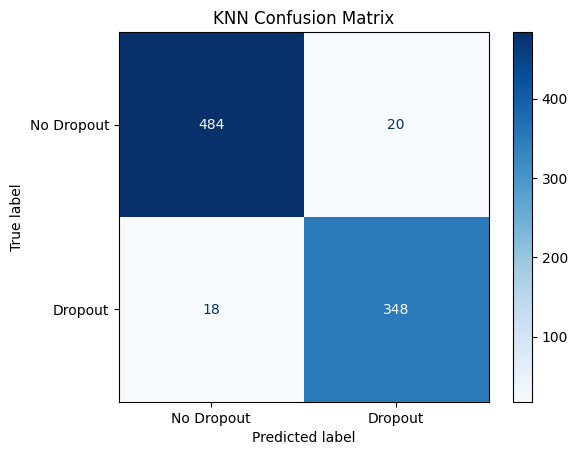

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

# KNN model reported as the best model in the article
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

y_pred = knn_model.predict(X_test)
y_probability = knn_model.predict_proba(X_test)[:, 1]

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_probability)

print("KNN with RFE, 22 features")
print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC AUC:   {auc:.4f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Dropout", "Dropout"]
)

display_cm.plot(cmap="Blues")
plt.title("KNN Confusion Matrix")
plt.show()

## 5- Methodologically Corrected Evaluation

In [10]:
# Methodologically corrected evaluation

# Start from the cleaned and encoded data before resampling
X_valid = df_cleaned.drop(columns=["Dropout"])
y_valid = df_cleaned["Dropout"]

# Split original observations first
X_train_valid, X_test_valid, y_train_valid, y_test_valid = train_test_split(
    X_valid,
    y_valid,
    test_size=0.20,
    random_state=42,
    stratify=y_valid
)

# Apply SMOTEENN only to the training set
smote_enn_valid = SMOTEENN(
    sampling_strategy=0.7,
    random_state=42
)

X_train_resampled, y_train_resampled = smote_enn_valid.fit_resample(
    X_train_valid,
    y_train_valid
)

# Fit RFE only on the resampled training set
rfe_valid = RFE(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    n_features_to_select=22,
    step=1
)

rfe_valid.fit(X_train_resampled, y_train_resampled)

valid_features = X_train_valid.columns[rfe_valid.support_].tolist()

X_train_final = pd.DataFrame(
    rfe_valid.transform(X_train_resampled),
    columns=valid_features
)

X_test_final = pd.DataFrame(
    rfe_valid.transform(X_test_valid),
    columns=valid_features
)

# Train and evaluate KNN
knn_valid = KNeighborsClassifier(n_neighbors=5)
knn_valid.fit(X_train_final, y_train_resampled)

y_pred_valid = knn_valid.predict(X_test_final)
y_prob_valid = knn_valid.predict_proba(X_test_final)[:, 1]

accuracy_valid = accuracy_score(y_test_valid, y_pred_valid)
precision_valid = precision_score(y_test_valid, y_pred_valid, zero_division=0)
recall_valid = recall_score(y_test_valid, y_pred_valid, zero_division=0)
f1_valid = f1_score(y_test_valid, y_pred_valid, zero_division=0)
auc_valid = roc_auc_score(y_test_valid, y_prob_valid)

print("Corrected evaluation")
print(f"Accuracy:  {accuracy_valid:.4f} ({accuracy_valid * 100:.2f}%)")
print(f"Precision: {precision_valid:.4f}")
print(f"Recall:    {recall_valid:.4f}")
print(f"F1-score:  {f1_valid:.4f}")
print(f"ROC AUC:   {auc_valid:.4f}")
print("\nSelected features:", valid_features)

Corrected evaluation
Accuracy:  0.7757 (77.57%)
Precision: 0.5000
Recall:    0.6305
F1-score:  0.5577
ROC AUC:   0.7604

Selected features: ['Gender', 'Age', 'Employment Status', 'Marital Status', 'Year', 'University Name', 'Faculty Name', 'Program Type', 'GPA', 'Failed Courses', 'Academic Warnings', 'Studying Difficulty', 'University Satisfaction', 'English Language', 'Language Barrier', 'Major Preknowledge', 'Family/Employer Pressure', 'Cultural Expectation', 'Commitments', 'Family/Friends Support', 'Psychological Issues', 'Health Issues']


## 6- Reproducibility Assessment

**Same number?** No. The reconstructed published workflow achieved 95.63% accuracy rather than the reported 97.6%. The corrected evaluation achieved only 77.57%.

**Valid?** No. The published performance does not provide a valid estimate for unseen students because SMOTEENN and RFE were applied before the training and test split.

**Problems?** The repository omits the ordinal encoding definitions and evaluation function, does not set a random seed for SMOTEENN, applies preprocessing before data splitting, and lacks repeated or external validation.

## 7- Conclusion

The study is partially reproducible because its data and code permit reconstruction of a result close to the published accuracy. However, the main performance claim is not methodologically validated. The substantial reduction observed under the corrected procedure suggests that the reported result was inflated by data leakage.